# 08. Correlaciones y relaciones (Tarea D)

Relaciones entre columnas de cada archivo (D1), entre estaciones con resolución común y rezagos (D2), correlación espuria frente a relación informativa (D3), medidas distintas de Pearson (D4) y una hipótesis hidrometeorológica (D5).

Decisiones que aplican a todo el notebook:

- Solo datos con bandera buena (1) del control propio (`parte2/salidas/`, generado por `python -m siata.pipeline`). Las series horarias vienen de `horario.parquet`, que ya se agregó solo con datos buenos; la excepción es la lluvia de la 35, que conserva los minutos sospechosos por desacuerdo entre balancines (ver la sección siguiente).
- Hora local de Colombia en todo. La 6004 ya viene corregida de UTC a hora local.
- Lluvia de la 35: media de los dos balancines (p1 y p2) en cada minuto.
- Desestacionalizar: restar el ciclo diario medio de cada hora calculado con los 30 días anteriores, sin mirar el futuro ni el propio día (`relaciones.ciclo_sin_futuro`). Diferenciar: primera diferencia de la serie.
- Intervalos del 95 % por bootstrap de bloques móviles: las series están autocorrelacionadas y el bootstrap clásico daría intervalos demasiado estrechos.
- Correlación no es causalidad. Cuando una relación tiene un mecanismo físico conocido se dice; cuando no, se deja como pregunta.

In [1]:
import sys; from pathlib import Path; sys.path.insert(0, str(Path.cwd().parent))
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from siata import relaciones as R
from siata.datos import DIR_SALIDAS, agregar
from siata.pipeline import DIR_RESULTADOS

reloj = time.time()
DIR_FIGURAS = Path.cwd().parent / "figuras"
DIR_FIGURAS.mkdir(exist_ok=True)
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
MESES = {12: "dic", 1: "ene", 2: "feb", 3: "mar", 4: "abr"}
fecha = lambda t: f"{t.day} {MESES[t.month]}"
GRIS = "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
                     "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
                     "legend.fontsize": 8, "legend.frameon": False})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)


def guardar(fig, nombre):
    fig.savefig(DIR_FIGURAS / f"08_{nombre}.png", dpi=110, bbox_inches="tight")


m367 = R.buenos("367")
m35 = R.buenos("35")
nivel = R.buenos("803")["nivel"]
lluvia35 = m35.mean(axis=1)  # media de los balancines; si uno no es bueno, queda el otro

horario = pd.read_parquet(DIR_SALIDAS / "horario.parquet").loc["2025-12-01":]  # la 6004 en hora local arranca el 30 nov a las 19 h
H = pd.DataFrame({"t": horario["367_t"], "h": horario["367_h"], "pr": horario["367_pr"], "p": horario["367_p"],
                  "rad": horario["6004_radiacion"], "lluvia35": horario[["35_p1", "35_p2"]].mean(axis=1)})
# presión de vapor (hPa) con la fórmula de la OMM-8 (2023), vol. I, anexo 4.B, ec. 4.B.1, sobre medias horarias
H["e"] = H["h"] / 100 * 6.112 * np.exp(17.62 * H["t"] / (243.12 + H["t"]))
print(f"367 minutal: {m367.shape}, 35: {m35.shape}, 803: {nivel.shape}, horario: {H.shape}")
print(H.describe().T.round(2))

367 minutal: (217440, 8), 35: (217440, 2), 803: (217440,), horario: (3624, 7)
           count    mean     std     min     25%     50%     75%      max
t         3620.0   19.33    3.01   13.82   17.00   18.34   21.35    27.69
h         3580.0   81.33   13.99   39.32   70.98   86.20   92.64   100.00
pr        3621.0  815.98    1.90  809.73  814.84  816.18  817.29   821.49
p         3560.0    0.07    0.43    0.00    0.00    0.00    0.00    10.80
rad       3573.0  211.97  315.65    0.00    0.00    1.44  375.20  1268.76
lluvia35  3624.0    0.24    1.63    0.00    0.00    0.00    0.00    43.18
e         3576.0   17.91    1.07   12.59   17.30   18.03   18.64    21.27


## Antes de empezar: qué le quita la bandera buena a la lluvia de la 35

En la 35 la única prueba que pone bandera 3 es `p1_p2_difieren`: si en una hora los dos balancines difieren en más de 0,508 mm (dos vueltas) y en más del 10 % de la lluvia de la hora, todos los minutos con lluvia de esa hora quedan sospechosos. Antes de correlacionar la lluvia con cualquier cosa conviene medir cuánto pesa esta bandera.

In [2]:
r35 = pd.read_parquet(DIR_SALIDAS / "minutal_35.parquet")
fallas = pd.read_parquet(DIR_SALIDAS / "fallas.parquet")
pruebas_35 = fallas.query("codigo == '35' and bandera == 3")["prueba"].unique().tolist()
assert pruebas_35 == ["p1_p2_difieren"], pruebas_35

total_mm, bueno_mm = r35[["p1", "p2"]].sum(), m35.sum()
horas = r35[["p1", "p2"]].resample("h").sum(min_count=1)
marcada = r35["b_p1"].eq(3).resample("h").max().astype(bool)
dif = (horas["p1"] - horas["p2"]).abs()
relativa = dif / horas[["p1", "p2"]].max(axis=1)
fuertes = horas["p1"] >= 5
print("lluvia total p1, p2 (mm):", total_mm.round(1).tolist(), "  con bandera buena:", bueno_mm.round(1).tolist())
print(f"se quita el {1 - bueno_mm['p1'] / total_mm['p1']:.1%} de la lluvia de p1, en {marcada.sum()} horas")
print(f"horas con p1 >= 5 mm: {fuertes.sum()}, marcadas: {(fuertes & marcada).sum()}")
print(f"diferencia relativa entre balancines en las horas marcadas con p1 >= 5 mm: mediana {relativa[marcada & fuertes].median():.1%}, "
      f"rango {relativa[marcada & fuertes].min():.1%} a {relativa[marcada & fuertes].max():.1%}")
exactas = marcada & ((dif / 0.254).round() == 2)
print(f"horas marcadas con diferencia de exactamente dos vueltas (0,508 mm): {exactas.sum()}")
print(pd.DataFrame({"p1_mm": horas["p1"], "p2_mm": horas["p2"], "diferencia_relativa": relativa})[marcada & fuertes]
      .sort_values("p1_mm", ascending=False).round(3))

# serie de sensibilidad: devuelve los minutos que solo tienen la bandera de p1_p2_difieren
lluvia35_sens = r35[["p1", "p2"]].where(r35[["b_p1", "b_p2"]].le(3).to_numpy()).mean(axis=1)

lluvia total p1, p2 (mm): [848.1, 858.3]   con bandera buena: [790.7, 803.4]
se quita el 6.8% de la lluvia de p1, en 10 horas
horas con p1 >= 5 mm: 47, marcadas: 6
diferencia relativa entre balancines en las horas marcadas con p1 >= 5 mm: mediana 13.1%, rango 11.1% a 17.4%
horas marcadas con diferencia de exactamente dos vueltas (0,508 mm): 0
                     p1_mm  p2_mm  diferencia_relativa
fecha_hora                                            
2026-04-16 23:00:00  8.636  7.620                0.118
2026-01-06 22:00:00  7.874  6.604                0.161
2026-01-11 09:00:00  7.620  6.604                0.133
2025-12-01 01:00:00  6.858  7.874                0.129
2026-04-17 21:00:00  6.096  6.858                0.111
2026-04-17 00:00:00  5.842  4.826                0.174


Con una tolerancia fija de 0,508 mm por hora, la bandera buena le quitaría a la 35 buena parte de su lluvia, justo en los aguaceros, porque la diferencia entre balancines crece con la intensidad (la OMM-8, 2023, vol. I, 6.5.2.2, explica que el error del balancín crece con la intensidad por el agua que se pierde durante el volteo). Por eso la regla de `calidad.py` usa una tolerancia relativa: la mayor entre 0,508 mm y el 10 % de la lluvia de la hora. Con esa regla (salida de arriba) la bandera buena quita el 6,8 % de la lluvia de p1, en 10 horas, y de las 47 horas con 5 mm o más solo 6 quedan sospechosas, todas con diferencias de 11 % a 17 % entre balancines.

En este notebook, D2 usa la serie buena, como pide el criterio general, y D5 (que necesita eventos completos) muestra los dos resultados: con bandera buena y con los minutos de `p1_p2_difieren` devueltos.

## Tabla de correlaciones que alimenta el dashboard

`registrar` calcula para cada par y versión Pearson, Spearman e información mutua (expresada como coeficiente de 0 a 1, ver D4), con intervalo del 95 % por bootstrap de bloques para Pearson y Spearman. El bloque es de 3 días en series horarias y de 1 día en series de 1 y 10 minutos.

In [3]:
filas = []
PASO_BLOQUE = {"1 min": 1440, "10 min": 144, "1 h": 72, "1 día": 7}


def tres(x, y):
    vx, vy = R.versiones(x), R.versiones(y)
    return {v: (vx[v], vy[v]) for v in vx}


def registrar(par, resolucion, pares, metodos=("pearson", "spearman", "info_mutua"), n_boot=300):
    bloque = PASO_BLOQUE[resolucion]
    nuevas = []
    for version, (x, y) in pares.items():
        for metodo in metodos:
            valor, n = R.correlacion(x, y, metodo)
            ic = R.ic_bootstrap_bloques(x, y, bloque, metodo, n_boot) if metodo != "info_mutua" else (np.nan, np.nan)
            nuevas.append({"par": par, "metodo": metodo, "version": version, "valor": valor, "n": n,
                           "ic95_inf": ic[0], "ic95_sup": ic[1], "resolucion": resolucion})
    filas.extend(nuevas)
    return pd.DataFrame(nuevas).pivot_table(index="version", columns="metodo", values="valor", sort=False).round(3)

## D1. Relaciones entre columnas de cada archivo

### Temperatura y humedad relativa en la 367 (1 h)

La humedad relativa no es una medida independiente de la temperatura: h = e / e_s(t), donde e es la presión de vapor (la humedad que de verdad trae el aire) y e_s(t) la presión de saturación, que crece con la temperatura. Si se separa e, se ve cuánto de la correlación t frente a h es pura definición.

t frente a h
 metodo              pearson  spearman  info_mutua
version                                          
cruda                -0.952    -0.913       0.943
desestacionalizada   -0.870    -0.810       0.882
diferenciada         -0.915    -0.868       0.912


t frente a e (presión de vapor, derivada de t y h)
 metodo              pearson  spearman  info_mutua
version                                          
cruda                 0.101     0.244       0.586
desestacionalizada   -0.067    -0.001       0.295
diferenciada          0.189     0.228       0.466
desviación estándar: h 14.0 %, e 1.07 hPa (media 17.9 hPa)


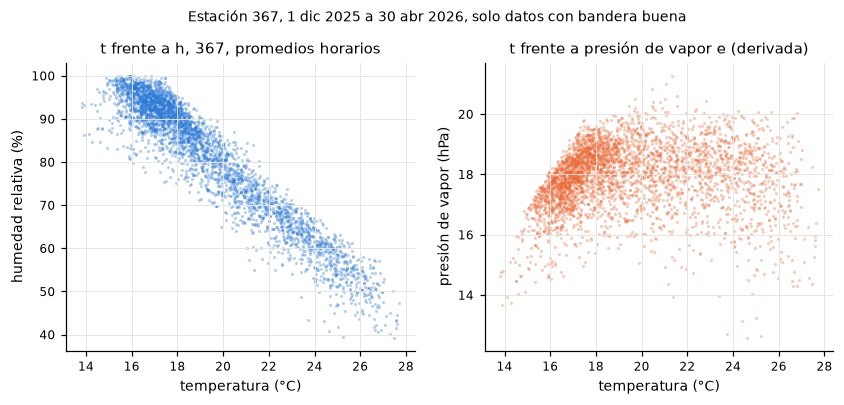

In [4]:
print("t frente a h\n", registrar("t 367 vs h 367 (1 h)", "1 h", tres(H["t"], H["h"])))
print("t frente a e (presión de vapor, derivada de t y h)\n",
      registrar("t 367 vs presion de vapor 367 (1 h)", "1 h", tres(H["t"], H["e"])))
print(f"desviación estándar: h {H['h'].std():.1f} %, e {H['e'].std():.2f} hPa (media {H['e'].mean():.1f} hPa)")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].scatter(H["t"], H["h"], s=4, color=COLORES[0], alpha=0.35, linewidths=0)
ax[0].set(xlabel="temperatura (°C)", ylabel="humedad relativa (%)", title="t frente a h, 367, promedios horarios")
ax[1].scatter(H["t"], H["e"], s=4, color=COLORES[1], alpha=0.35, linewidths=0)
ax[1].set(xlabel="temperatura (°C)", ylabel="presión de vapor (hPa)", title="t frente a presión de vapor e (derivada)")
fig.suptitle("Estación 367, 1 dic 2025 a 30 abr 2026, solo datos con bandera buena", fontsize=9, y=1.02)
guardar(fig, "t_h_presion_vapor")
plt.show()

La correlación t frente a h es -0,95 y casi no cambia al quitar el ciclo (-0,87), pero buena parte es definición. La presión de vapor e tiene correlación lineal de apenas 0,10 con t. La información mutua (0,59) muestra que e sí depende de t, pero no de forma lineal: en la figura e sube con t hasta unos 18 °C y luego se aplana. Para un modelo, t y h no son dos predictores independientes; si se quiere la humedad como variable propia conviene usar e o el punto de rocío.

### Temperatura y presión en la 367 (1 h)

La presión tiene una marea atmosférica semidiurna (dos máximos y dos mínimos al día) y la temperatura un ciclo diurno simple; parte de la correlación viene de ahí. Se revisa también con medias diarias, donde ya no hay ciclo diurno.

In [5]:
print("t frente a pr\n", registrar("t 367 vs pr 367 (1 h)", "1 h", tres(H["t"], H["pr"])))
ciclo = H[["t", "pr"]].groupby(H.index.hour).mean()
print("hora del máximo y del mínimo medio: t", ciclo["t"].idxmax(), ciclo["t"].idxmin(),
      "| pr", ciclo["pr"].idxmax(), ciclo["pr"].idxmin(), f"| amplitud media pr {ciclo['pr'].max() - ciclo['pr'].min():.1f} hPa")
print("presión media por hora:", ciclo["pr"].round(1).to_dict())
diario = H[["t", "pr"]].resample("D").mean()
print(f"medias diarias: Pearson t-pr {diario['t'].corr(diario['pr']):.3f}; "
      f"cambios de un día al siguiente {diario['t'].diff().corr(diario['pr'].diff()):.3f}")

t frente a pr
 metodo              pearson  spearman  info_mutua
version                                          
cruda                -0.615    -0.522       0.692
desestacionalizada   -0.609    -0.630       0.678
diferenciada         -0.422    -0.393       0.577
hora del máximo y del mínimo medio: t 13 6 | pr 8 15 | amplitud media pr 5.1 hPa
presión media por hora: {0: 816.8, 1: 816.4, 2: 816.0, 3: 815.9, 4: 816.0, 5: 816.4, 6: 817.0, 7: 817.8, 8: 818.3, 9: 818.2, 10: 817.5, 11: 816.5, 12: 815.2, 13: 814.1, 14: 813.4, 15: 813.2, 16: 813.4, 17: 813.9, 18: 814.6, 19: 815.4, 20: 816.3, 21: 816.9, 22: 817.2, 23: 817.2}
medias diarias: Pearson t-pr -0.637; cambios de un día al siguiente -0.694


La presión tiene su máximo medio a las 8 h y su mínimo a las 15 h, con 5,1 hPa de amplitud (marea semidiurna), y la temperatura su máximo a las 13 h. La correlación es -0,62 en crudo y casi igual sin el ciclo (-0,61); con medias diarias es -0,64. O sea que no es solo ciclo compartido: los días más calientes tienen presión más baja. Con estos datos no puedo decir por qué (podría ser de escala sinóptica), así que lo dejo como pregunta abierta y no lo uso en ninguna regla de calidad.

### Velocidad media y ráfaga en la 367 (1 min)

In [6]:
vv, vmax = m367["vv"], m367["vv_max"]
print("vv frente a vv_max\n", registrar("vv 367 vs vv_max 367 (1 min)", "1 min", tres(vv, vmax), n_boot=200))
ambos = pd.concat([vv, vmax], axis=1).dropna()
con_viento = ambos[ambos["vv"] > 0]
pendiente, intercepto = np.polyfit(ambos["vv"], ambos["vv_max"], 1)
print(f"minutos con vv_max < vv: {(ambos['vv_max'] < ambos['vv']).sum()} de {len(ambos)}")
print(f"factor de ráfaga vv_max / vv (vv > 0): mediana {(con_viento['vv_max'] / con_viento['vv']).median():.2f}, "
      f"percentiles 10 y 90 {(con_viento['vv_max'] / con_viento['vv']).quantile([.1, .9]).round(2).tolist()}")
print(f"recta vv_max = {pendiente:.2f} vv + {intercepto:.2f}")
multiplo = lambda s, paso: ((s / paso).round() * paso - s).abs().lt(1e-6).mean()
print(f"valores múltiplos de 0,1 m/s: vv {multiplo(vv.dropna(), 0.1):.1%}, vv_max {multiplo(vmax.dropna(), 0.1):.1%}")

vv frente a vv_max
 metodo              pearson  spearman  info_mutua
version                                          
cruda                 0.874     0.862       0.903
desestacionalizada    0.842     0.823       0.868
diferenciada          0.686     0.677       0.748
minutos con vv_max < vv: 0 de 215069
factor de ráfaga vv_max / vv (vv > 0): mediana 1.71, percentiles 10 y 90 [1.28, 3.25]
recta vv_max = 1.53 vv + 0.20
valores múltiplos de 0,1 m/s: vv 10.0%, vv_max 100.0%


vv y vv_max están muy relacionadas (0,874) pero no son redundantes. La ráfaga nunca es menor que la media, y el factor de ráfaga va de 1,28 a 3,25 entre los percentiles 10 y 90: trae información de turbulencia que la media no tiene. Tampoco parece calculada a partir de vv: vv_max siempre es múltiplo de 0,1 m/s y vv solo el 10 % de las veces, lo que sugiere (inferido) dos procesos distintos, por ejemplo la ráfaga como máximo de muestras instantáneas y vv como promedio del minuto.

### Dirección media y dirección de la ráfaga en la 367 (1 min)

Las direcciones son ángulos: 359° y 1° están a 2°, no a 358°. Se usa la correlación circular y la diferencia angular por el camino corto. Pearson sobre grados se muestra solo para ver cuánto se equivoca.

dv frente a dv_max
 metodo   circular
version          
cruda       0.809
                minutos  circular  pearson_grados  dif_mediana  dif_p90  dif_mayor_90
vv                                                                                   
vv <= 0,5 m/s   84701.0     0.732           0.631         18.0    105.0         0.124
0,5 a 1,5 m/s  112580.0     0.849           0.756         10.0     86.0         0.095
> 1,5 m/s       17767.0     0.819           0.781          8.0     85.0         0.094
todo el periodo: circular 0.809, Pearson sobre grados 0.711, diferencia mediana 12°


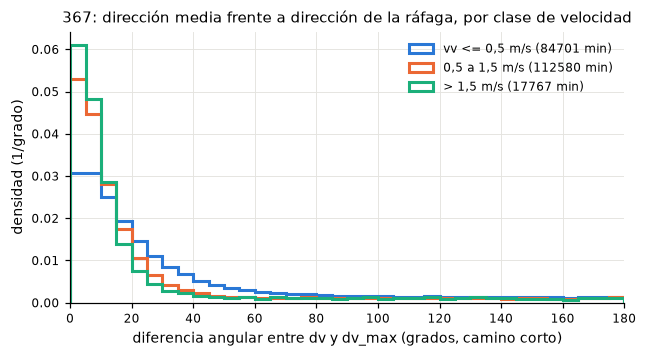

In [7]:
dv, dmax = m367["dv"], m367["dv_max"]
print("dv frente a dv_max\n",
      registrar("dv 367 vs dv_max 367 (1 min)", "1 min", {"cruda": (dv, dmax)}, metodos=("circular",), n_boot=200))
ang = pd.DataFrame({"dv": dv, "dv_max": dmax, "vv": vv}).dropna()
ang["dif"] = R.diferencia_angular(ang["dv"], ang["dv_max"])
clases = pd.cut(ang["vv"], [-0.01, 0.5, 1.5, 100], labels=["vv <= 0,5 m/s", "0,5 a 1,5 m/s", "> 1,5 m/s"])
resumen_dir = ang.groupby(clases, observed=True).apply(lambda g: pd.Series({
    "minutos": len(g), "circular": R.correlacion(g["dv"], g["dv_max"], "circular")[0],
    "pearson_grados": g["dv"].corr(g["dv_max"]), "dif_mediana": g["dif"].median(),
    "dif_p90": g["dif"].quantile(0.9), "dif_mayor_90": (g["dif"] > 90).mean()}))
print(resumen_dir.round(3))
print(f"todo el periodo: circular {R.correlacion(ang['dv'], ang['dv_max'], 'circular')[0]:.3f}, "
      f"Pearson sobre grados {ang['dv'].corr(ang['dv_max']):.3f}, diferencia mediana {ang['dif'].median():.0f}°")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
bordes = np.arange(0, 181, 5)
for i, (nombre, g) in enumerate(ang.groupby(clases, observed=True)):
    ax.hist(g["dif"], bins=bordes, density=True, histtype="step", linewidth=2, color=COLORES[i], label=f"{nombre} ({len(g)} min)")
ax.set(xlabel="diferencia angular entre dv y dv_max (grados, camino corto)", ylabel="densidad (1/grado)",
       title="367: dirección media frente a dirección de la ráfaga, por clase de velocidad", xlim=(0, 180))
ax.legend()
guardar(fig, "direccion_media_rafaga")
plt.show()

La correlación circular entre dv y dv_max es 0,81; Pearson sobre grados da 0,71 porque trata 359° y 1° como opuestos. La diferencia angular mediana es 12° y depende del viento: 18° con 0,5 m/s o menos y 8° con más de 1,5 m/s. Con calma la dirección es poco confiable (el 12 % de esos minutos tienen más de 90° entre las dos). Ojo con leer solo el coeficiente: en la clase de más viento baja de 0,85 a 0,82 aunque la diferencia angular mejora, porque con viento fuerte las direcciones se concentran y queda poca varianza que correlacionar. Para hablar de redundancia entre direcciones, la diferencia angular es más útil que el coeficiente.

### Lluvia y humedad (1 h)

La lluvia tiene muchas horas en cero y unas pocas muy grandes; ahí Pearson es mala medida. Se muestran Pearson, Spearman e información mutua y, sobre todo, la humedad por clase de lluvia, que se lee directo.

p 367 frente a h 367
 metodo              pearson  spearman  info_mutua
version                                          
cruda                 0.106     0.142       0.302
desestacionalizada    0.266     0.244       0.358
diferenciada          0.153     0.042       0.331


lluvia 35 frente a h 367
 metodo              pearson  spearman  info_mutua
version                                          
cruda                 0.094     0.219       0.284
desestacionalizada    0.235     0.197       0.285
diferenciada          0.152     0.044       0.274
horas con lluvia en la 367: 18.4%; en la 35: 9.8%
lluvia de la 35 entre las 12 y las 18 h: 48%; hora del mínimo medio de h: 13 h
mediana de h (%) por clase de lluvia horaria
                35   367
seca         84.9  85.6
hasta 1 mm   93.4  87.0
1 a 5 mm     90.8  91.8
más de 5 mm  94.3  96.1
horas en que solo la 367 registra lluvia: 342 (8.5 mm de 260.0), lluvia mediana 0.02 mm (menos de una vuelta del balancín de la 35), 64% entre 9 y 17 h
h mediana: solo 367 79.0 %, secas 85.5 %  (parece más seco, pero es la hora del día)
misma franja de 9 a 17 h: solo 367 71.0 %, secas 64.4 %; anomalía de h sin ciclo: solo 367 +2.7, secas -1.4 puntos


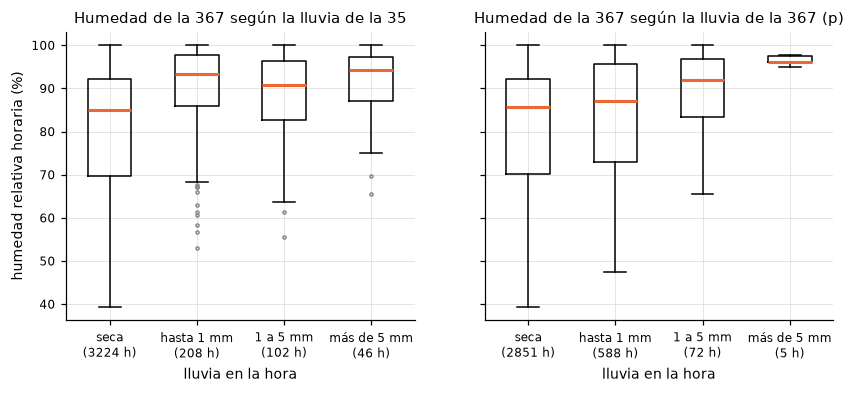

In [8]:
print("p 367 frente a h 367\n", registrar("p 367 vs h 367 (1 h)", "1 h", tres(H["p"], H["h"])))
print("lluvia 35 frente a h 367\n", registrar("lluvia 35 vs h 367 (1 h)", "1 h", tres(H["lluvia35"], H["h"])))
print(f"horas con lluvia en la 367: {(H['p'] > 0).mean():.1%}; en la 35: {(H['lluvia35'] > 0).mean():.1%}")
tarde = (H.index.hour >= 12) & (H.index.hour <= 18)
print(f"lluvia de la 35 entre las 12 y las 18 h: {H.loc[tarde, 'lluvia35'].sum() / H['lluvia35'].sum():.0%}; "
      f"hora del mínimo medio de h: {H['h'].groupby(H.index.hour).mean().idxmin()} h")
cortes = [-0.01, 0, 1, 5, 1000]
etiquetas = ["seca", "hasta 1 mm", "1 a 5 mm", "más de 5 mm"]
por_clase = pd.DataFrame({"35": H.groupby(pd.cut(H["lluvia35"], cortes, labels=etiquetas), observed=True)["h"].median(),
                          "367": H.groupby(pd.cut(H["p"], cortes, labels=etiquetas), observed=True)["h"].median()})
print("mediana de h (%) por clase de lluvia horaria\n", por_clase.round(1))
solo367 = (H["p"] > 0) & (H["lluvia35"] == 0)
seca = (H["p"] == 0) & (H["lluvia35"] == 0)
de_dia = (H.index.hour >= 9) & (H.index.hour <= 17)
anom_h = R.versiones(H["h"])["desestacionalizada"]
print(f"horas en que solo la 367 registra lluvia: {solo367.sum()} ({H.loc[solo367, 'p'].sum():.1f} mm de {H['p'].sum():.1f}), "
      f"lluvia mediana {H.loc[solo367, 'p'].median():.2f} mm (menos de una vuelta del balancín de la 35), "
      f"{(solo367 & de_dia).sum() / solo367.sum():.0%} entre 9 y 17 h")
print(f"h mediana: solo 367 {H.loc[solo367, 'h'].median():.1f} %, secas {H.loc[seca, 'h'].median():.1f} %  (parece más seco, pero es la hora del día)")
print(f"misma franja de 9 a 17 h: solo 367 {H.loc[solo367 & de_dia, 'h'].median():.1f} %, secas {H.loc[seca & de_dia, 'h'].median():.1f} %; "
      f"anomalía de h sin ciclo: solo 367 {anom_h[solo367].median():+.1f}, secas {anom_h[seca].median():+.1f} puntos")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for a, (col, nombre) in zip(ax, [("lluvia35", "lluvia de la 35"), ("p", "lluvia de la 367 (p)")]):
    cl = pd.cut(H[col], cortes, labels=etiquetas)
    datos = [H.loc[cl == e, "h"].dropna() for e in etiquetas]
    a.boxplot(datos, tick_labels=[f"{e}\n({len(d)} h)" for e, d in zip(etiquetas, datos)], widths=0.5,
              medianprops={"color": COLORES[1], "linewidth": 2}, flierprops={"markersize": 2, "markeredgecolor": GRIS})
    a.set(title=f"Humedad de la 367 según la {nombre}", xlabel="lluvia en la hora")
ax[0].set_ylabel("humedad relativa horaria (%)")
guardar(fig, "humedad_por_lluvia")
plt.show()

Con lluvia, Pearson casi no ve nada (0,106 con la 367 y 0,094 con la 35) porque la mayoría de las horas son cero. Spearman e información mutua ven un poco más, y la mediana de h pasa de 84,9 % en horas secas a más de 90 % en horas con lluvia de la 35. Aquí quitar el ciclo sube la correlación con la 35 de 0,094 a 0,235: la lluvia cae sobre todo en la tarde, cuando h está en su mínimo diario, y el ciclo compartido tapaba la relación en lugar de inflarla.

De paso aparece algo para la Tarea C. Hay 342 horas en que solo la 367 registra lluvia, con mediana de 0,02 mm, menos de una vuelta del balancín de la 35. Vistas en bruto parecen horas más secas que las secas, pero es la hora del día: en la misma franja de 9 a 17 h tienen más humedad que las horas secas, y la anomalía sin ciclo también es positiva. Eso apunta a llovizna real que la 35 no alcanza a medir por resolución, y matiza la lectura del código 1511 de la 367 como "lluvia sin respaldo de la 35" (inferido, no confirmado).

### p1 frente a p2 en la 35: redundancia de sensores

Dos balancines de 0,254 mm en el mismo sitio. A 1 minuto la vuelta de uno y otro no cae en el mismo minuto (la OMM-8, vol. I, 6.5.2.2, lo describe como error de muestreo del balancín); al agregar, esa diferencia desaparece.

In [9]:
for res, freq in [("1 min", "min"), ("10 min", "10min"), ("1 h", "h"), ("1 día", "D")]:
    a = m35["p1"] if freq == "min" else agregar(m35["p1"], "p1", freq, 0.9)
    b = m35["p2"] if freq == "min" else agregar(m35["p2"], "p2", freq, 0.9)
    print(res, registrar(f"p1 35 vs p2 35 ({res})", res, {"cruda": (a, b)}, n_boot=200).to_dict("records"))
con_agua = (m35["p1"] > 0) | (m35["p2"] > 0)
print(f"minutos con lluvia en que voltean los dos: {((m35['p1'] > 0) & (m35['p2'] > 0))[con_agua].mean():.1%}")
cc_p1p2 = R.correlacion_cruzada(m35["p1"], m35["p2"], range(-5, 6))
print("correlación cruzada p1 -> p2 a 1 min:", cc_p1p2.round(3).to_dict())
dias = pd.DataFrame({v: agregar(m35[v], v, "D", 0.9) for v in ("p1", "p2")}).dropna()
print(f"días completos: {len(dias)}, total p1 {dias['p1'].sum():.1f} mm, p2 {dias['p2'].sum():.1f} mm, "
      f"pendiente p2 = b p1 por el origen: {(dias['p1'] * dias['p2']).sum() / (dias['p1'] ** 2).sum():.3f}")

1 min [{'pearson': 0.861, 'spearman': 0.603, 'info_mutua': 0.228}]


10 min [{'pearson': 0.994, 'spearman': 0.802, 'info_mutua': 0.496}]
1 h [{'pearson': 0.999, 'spearman': 0.886, 'info_mutua': 0.722}]
1 día [{'pearson': 0.999, 'spearman': 0.99, 'info_mutua': 0.994}]
minutos con lluvia en que voltean los dos: 43.4%
correlación cruzada p1 -> p2 a 1 min: {-5: 0.57, -4: 0.615, -3: 0.668, -2: 0.724, -1: 0.801, 0: 0.861, 1: 0.796, 2: 0.727, 3: 0.668, 4: 0.624, 5: 0.578}


días completos: 151, total p1 790.7 mm, p2 803.4 mm, pendiente p2 = b p1 por el origen: 1.011


A 1 minuto Pearson es 0,86 y solo en el 43 % de los minutos con lluvia voltean los dos. La correlación cruzada tiene su máximo en rezago 0 y cae casi igual hacia los dos lados, así que no hay desfase de reloj: es la vuelta que cae en minutos distintos. A 10 minutos ya es 0,994 y por hora 0,999, con pendiente de 1,011 en días completos. Son redundantes desde 10 minutos, y esa redundancia sirve: permite ver cuándo uno de los dos se tapa o se descalibra. Spearman da menos a 1 minuto (0,60) por los empates en cero, no porque la relación sea débil.

## D2. Relaciones entre estaciones

Resolución común explícita en cada par y rezagos con `correlacion_cruzada` (rezago positivo: la segunda serie va después de la primera).

### Lluvia de la 35 y nivel de la 803 (10 min, unos 240 m)

Lluvia en 10 minutos (suma, cobertura mínima 90 %) frente al nivel medio en 10 minutos (cobertura 75 %) y frente a su subida (diferencia entre ventanas consecutivas). Rezagos de -60 a 180 minutos.

In [10]:
L10 = agregar(lluvia35, "p1", "10min", 0.9)
N10 = agregar(nivel, "nivel", "10min", 0.75)
pares_ln = {"cruda": (L10, N10), "diferenciada": (L10, N10.diff())}
print(registrar("lluvia 35 vs nivel 803 (10 min)", "10 min", pares_ln))
cruzadas = []
for version, (x, y) in pares_ln.items():
    cc = R.correlacion_cruzada(x, y, range(-60, 190, 10))
    cruzadas.append(cc.reset_index().assign(par="lluvia 35 vs nivel 803 (10 min)", version=version))
    sp = R.correlacion_cruzada(x, y, range(0, 190, 10), "spearman")
    print(f"{version}: Pearson máximo {cc.max():.3f} a {cc.idxmax()} min; Spearman máximo {sp.max():.3f} a {sp.idxmax()} min")
print(f"ventanas de 10 min con lluvia: {(L10 > 0).mean():.1%} de {L10.notna().sum()}")
print(f"ruido del nivel: cambio mediano entre minutos {nivel.diff().abs().median():.2f} cm, "
      f"desviación estándar del cambio {nivel.diff().std():.2f} cm")

metodo        pearson  spearman  info_mutua
version                                    
cruda           0.117     0.147       0.220
diferenciada    0.065     0.019       0.117
cruda: Pearson máximo 0.124 a 10 min; Spearman máximo 0.148 a 10 min
diferenciada: Pearson máximo 0.065 a 0 min; Spearman máximo 0.019 a 0 min
ventanas de 10 min con lluvia: 4.1% de 21720
ruido del nivel: cambio mediano entre minutos 0.20 cm, desviación estándar del cambio 1.18 cm


La correlación cruzada entre lluvia y nivel es débil: el máximo con el nivel medio es 0,124 a 10 minutos y con la subida 0,065 en rezago 0. La forma sí es la esperada: crece de 0 a 10 minutos, luego cae, y con rezagos negativos (el nivel antes de la lluvia) es menor. Es débil porque solo el 4,1 % de las ventanas de 10 minutos tiene lluvia, casi toda débil, y el nivel tiene un ruido del mismo orden que su respuesta: el cambio mediano entre minutos es 0,20 cm pero la desviación estándar es 1,18 cm por los picos de un minuto. La quebrada sí responde, pero de forma intermitente y solo con aguaceros, y por eso D5 lo mira por eventos.

### Radiación de la 6004 y temperatura y humedad de la 367 (1 h, unos 22 km)

Rezagos de -6 a 6 horas. Como comprobación del reloj, se repite con la radiación sin corregir de UTC a hora local.

In [11]:
print("radiación 6004 frente a t 367\n", registrar("radiacion 6004 vs t 367 (1 h)", "1 h", tres(H["rad"], H["t"])))
print("radiación 6004 frente a h 367\n", registrar("radiacion 6004 vs h 367 (1 h)", "1 h", tres(H["rad"], H["h"])))
rezagos_h = range(-360, 361, 60)
for nombre, y in [("t", H["t"]), ("h", H["h"])]:
    for version, (a, b) in tres(H["rad"], y).items():
        cc = R.correlacion_cruzada(a, b, rezagos_h)
        cruzadas.append(cc.reset_index().assign(par=f"radiacion 6004 vs {nombre} 367 (1 h)", version=version))
        mejor = cc.abs().idxmax()
        print(f"rad -> {nombre}, {version}: máximo |r| = {cc[mejor]:.3f} a {mejor // 60} h")
sin_corregir = H["rad"].shift(5)  # lo que se vería si se leyera la 6004 como hora local: 5 h tarde
cc = R.correlacion_cruzada(sin_corregir, H["t"], rezagos_h)
cruzadas.append(cc.reset_index().assign(par="radiacion 6004 SIN corregir reloj vs t 367 (1 h)", version="cruda"))
print(f"sin corregir el reloj: máximo {cc.max():.3f} a {cc.idxmax() // 60} h (la temperatura 'antes' que el sol)")

diario = H[["rad", "t", "h"]].resample("D").mean().where(H[["rad", "t", "h"]].resample("D").count() >= 20)
for nombre in ("t", "h"):
    print(f"medias diarias rad frente a {nombre}\n",
          registrar(f"radiacion 6004 vs {nombre} 367 (1 día)", "1 día",
                    {"cruda": (diario["rad"], diario[nombre]), "diferenciada": (diario["rad"].diff(), diario[nombre].diff())}))

radiación 6004 frente a t 367
 metodo              pearson  spearman  info_mutua
version                                          
cruda                 0.711     0.651       0.710
desestacionalizada    0.438     0.345       0.419
diferenciada          0.479     0.496       0.768


radiación 6004 frente a h 367
 metodo              pearson  spearman  info_mutua
version                                          
cruda                -0.676    -0.631       0.674
desestacionalizada   -0.425    -0.369       0.458
diferenciada         -0.441    -0.461       0.673
rad -> t, cruda: máximo |r| = 0.847 a 2 h
rad -> t, desestacionalizada: máximo |r| = 0.504 a 1 h
rad -> t, diferenciada: máximo |r| = 0.606 a 1 h
rad -> h, cruda: máximo |r| = -0.818 a 2 h
rad -> h, desestacionalizada: máximo |r| = -0.481 a 1 h
rad -> h, diferenciada: máximo |r| = -0.565 a 1 h
sin corregir el reloj: máximo 0.847 a -3 h (la temperatura 'antes' que el sol)


medias diarias rad frente a t
 metodo        pearson  spearman  info_mutua
version                                    
cruda           0.550     0.501       0.324
diferenciada    0.587     0.557       0.570
medias diarias rad frente a h
 metodo        pearson  spearman  info_mutua
version                                    
cruda          -0.570    -0.545       0.606
diferenciada   -0.612    -0.618       0.578


En crudo la radiación y la temperatura van con 0,71 en rezago 0 y 0,847 con la temperatura 2 horas después: el aire se demora en calentarse. Si la 6004 se leyera como hora local, sin corregir, el máximo caería en -3 h, es decir, la temperatura subiría antes que el sol. Esa es una segunda comprobación, independiente de la radiación extraterrestre, de que la 6004 está en UTC.

### Lluvia de la 367 y de la 35: mismo sitio, comprobación de relojes (1 min)

In [12]:
p367 = m367["p"]
print(registrar("p 367 vs lluvia 35 (1 min)", "1 min", {"cruda": (p367, lluvia35)}, n_boot=200))
cc = R.correlacion_cruzada(p367, lluvia35, range(-15, 16))
cruzadas.append(cc.reset_index().assign(par="p 367 vs lluvia 35 (1 min)", version="cruda"))
cruzadas.append(cc_p1p2.reset_index().assign(par="p1 35 vs p2 35 (1 min)", version="cruda"))
print(f"máximo {cc.max():.3f} a {cc.idxmax()} min; a -1 y +1 min: {cc[-1]:.3f} y {cc[1]:.3f}")
cc5 = R.correlacion_cruzada(agregar(p367, "p", "5min", 0.9), agregar(lluvia35, "p1", "5min", 0.9), range(-30, 31, 5))
print("a 5 min:", cc5.round(3).to_dict())
comun = pd.concat([p367, lluvia35], axis=1, keys=["p367", "l35"]).dropna()
print(f"en minutos comunes: 367 suma {comun['p367'].sum():.1f} mm, 35 suma {comun['l35'].sum():.1f} mm "
      f"(cociente {comun['p367'].sum() / comun['l35'].sum():.2f}) aunque la correlación sea alta")

metodo   pearson  spearman  info_mutua
version                               
cruda      0.926     0.523       0.327
máximo 0.926 a 0 min; a -1 y +1 min: 0.865 y 0.879
a 5 min: {-30: 0.167, -25: 0.209, -20: 0.278, -15: 0.381, -10: 0.535, -5: 0.76, 0: 0.977, 5: 0.788, 10: 0.562, 15: 0.399, 20: 0.287, 25: 0.205, 30: 0.155}
en minutos comunes: 367 suma 253.6 mm, 35 suma 793.8 mm (cociente 0.32) aunque la correlación sea alta


Los relojes de la 367 y la 35 están alineados al minuto: la correlación cruzada tiene su máximo en rezago 0 tanto a 1 minuto (0,926) como a 5 minutos (0,977). Pero correlación alta no es acuerdo: en los mismos minutos la 367 suma solo el 32 % de lo que suma la 35 (253,6 frente a 793,8 mm, con la media de los dos balancines). Pearson no ve diferencias de escala; para comparar sensores hace falta además el sesgo o la pendiente.

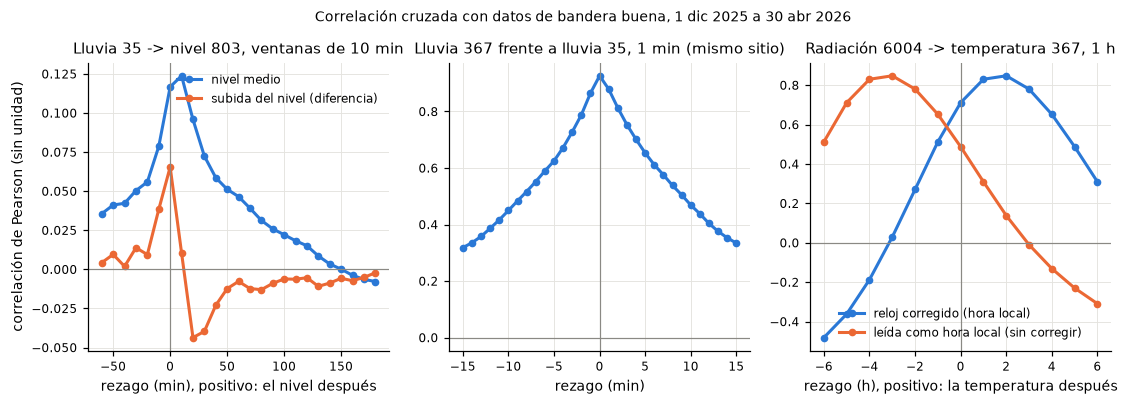

In [13]:
cruz = pd.concat(cruzadas, ignore_index=True)[["par", "version", "rezago_min", "valor"]]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for i, (version, g) in enumerate(cruz[cruz["par"] == "lluvia 35 vs nivel 803 (10 min)"].groupby("version")):
    ax[0].plot(g["rezago_min"], g["valor"], marker="o", markersize=4, color=COLORES[i],
               label="nivel medio" if version == "cruda" else "subida del nivel (diferencia)")
ax[0].set(title="Lluvia 35 -> nivel 803, ventanas de 10 min", xlabel="rezago (min), positivo: el nivel después",
          ylabel="correlación de Pearson (sin unidad)")
ax[0].legend()
g = cruz[cruz["par"] == "p 367 vs lluvia 35 (1 min)"]
ax[1].plot(g["rezago_min"], g["valor"], marker="o", markersize=4, color=COLORES[0])
ax[1].set(title="Lluvia 367 frente a lluvia 35, 1 min (mismo sitio)", xlabel="rezago (min)")
for i, (par, nombre) in enumerate([("radiacion 6004 vs t 367 (1 h)", "reloj corregido (hora local)"),
                                   ("radiacion 6004 SIN corregir reloj vs t 367 (1 h)", "leída como hora local (sin corregir)")]):
    g = cruz[(cruz["par"] == par) & (cruz["version"] == "cruda")]
    ax[2].plot(g["rezago_min"] / 60, g["valor"], marker="o", markersize=4, color=COLORES[i], label=nombre)
ax[2].set(title="Radiación 6004 -> temperatura 367, 1 h", xlabel="rezago (h), positivo: la temperatura después")
ax[2].legend()
for a in ax:
    a.axhline(0, color=GRIS, linewidth=0.8)
    a.axvline(0, color=GRIS, linewidth=0.8)
fig.suptitle("Correlación cruzada con datos de bandera buena, 1 dic 2025 a 30 abr 2026", fontsize=9, y=1.02)
guardar(fig, "correlacion_cruzada")
plt.show()

## D3. Correlación espuria frente a relación informativa

La radiación de Barbosa y la temperatura de La Ladera están a 22 km: comparten el ciclo del sol, y eso solo ya da una correlación alta. La pregunta es qué queda cuando se quita ese ciclo.

In [14]:
corr = pd.DataFrame(filas)
pares_d3 = ["radiacion 6004 vs t 367 (1 h)", "radiacion 6004 vs h 367 (1 h)", "t 367 vs h 367 (1 h)",
            "t 367 vs pr 367 (1 h)", "lluvia 35 vs h 367 (1 h)"]
d3 = corr[(corr["metodo"] == "pearson") & corr["par"].isin(pares_d3)]
print(d3.pivot_table(index="par", columns="version", values="valor", sort=False)
      [["cruda", "desestacionalizada", "diferenciada"]].round(3))
print(d3[["par", "version", "valor", "ic95_inf", "ic95_sup", "n"]].round(3).to_string(index=False))

rad_v, t_v = R.versiones(H["rad"]), R.versiones(H["t"])
print(f"\nrad-t con diferencia de 24 h (quita el ciclo): {H['rad'].diff(24).corr(H['t'].diff(24)):.3f}; "
      f"con diferencia de 1 h: {H['rad'].diff().corr(H['t'].diff()):.3f}")
ciclo_todo = lambda s: s - s.groupby(s.index.hour).transform("mean")
print(f"anomalía con el ciclo de todo el periodo (mira el futuro): {ciclo_todo(H['rad']).corr(ciclo_todo(H['t'])):.3f}; "
      f"sin futuro: {rad_v['desestacionalizada'].corr(t_v['desestacionalizada']):.3f}")
horas_sol = (H.index.hour >= 8) & (H.index.hour <= 16)
print(f"anomalías solo entre 8 y 16 h: {rad_v['desestacionalizada'][horas_sol].corr(t_v['desestacionalizada'][horas_sol]):.3f}")
anom_d = pd.DataFrame({"rad": rad_v["desestacionalizada"], "t": t_v["desestacionalizada"]}).resample("D").mean()
print(f"media diaria de las anomalías horarias: Pearson {anom_d['rad'].corr(anom_d['t']):.3f}, "
      f"Spearman {anom_d['rad'].corr(anom_d['t'], method='spearman'):.3f}, {anom_d.dropna().shape[0]} días")
print("los 5 días con la radiación más baja frente a su ciclo (W/m² y °C):")
print(anom_d.nsmallest(5, "rad").round(1))

version                        cruda  desestacionalizada  diferenciada
par                                                                   
t 367 vs h 367 (1 h)          -0.952              -0.870        -0.915
t 367 vs pr 367 (1 h)         -0.615              -0.609        -0.422
lluvia 35 vs h 367 (1 h)       0.094               0.235         0.152
radiacion 6004 vs t 367 (1 h)  0.711               0.438         0.479
radiacion 6004 vs h 367 (1 h) -0.676              -0.425        -0.441
                          par            version  valor  ic95_inf  ic95_sup    n
         t 367 vs h 367 (1 h)              cruda -0.952    -0.961    -0.940 3576
         t 367 vs h 367 (1 h) desestacionalizada -0.870    -0.908    -0.825 3408
         t 367 vs h 367 (1 h)       diferenciada -0.915    -0.924    -0.906 3550
        t 367 vs pr 367 (1 h)              cruda -0.615    -0.638    -0.587 3617
        t 367 vs pr 367 (1 h) desestacionalizada -0.609    -0.665    -0.542 3449
        t 367 vs 

Al quitar el ciclo diurno la correlación radiación frente a temperatura baja de 0,71 a 0,44 (IC 95 % de 0,38 a 0,49). Esa diferencia es el ciclo del sol que comparten las dos estaciones y no dice nada nuevo. Diferenciar una hora no basta: la radiación y la temperatura suben juntas cada mañana, así que la primera diferencia conserva el ciclo (0,48, e información mutua de 0,77). La diferencia de 24 horas, que sí quita el ciclo, da 0,44, igual que la anomalía. Usar el ciclo de todo el periodo, mirando el futuro, da prácticamente lo mismo (0,439 frente a 0,438), así que la elección no mueve el resultado.

Lo que queda es informativo: la nubosidad regional. Con medias diarias de las anomalías la correlación es 0,56 en 144 días, y la figura de abajo muestra rachas de días nublados (anomalía negativa de radiación) que coinciden con días frescos en La Ladera, a 22 km. No es causalidad: la radiación de Barbosa no calienta La Ladera; las dos responden a la misma nubosidad. Sirve, por ejemplo, como apoyo para la coherencia espacial de la 367 cuando falte un dato.

En los otros pares: t frente a h casi no cambia (-0,87 sin ciclo) porque es en buena parte definición (D1); t frente a pr tampoco (-0,61), y queda como pregunta abierta; y lluvia frente a h sube de 0,094 a 0,235 al quitar el ciclo, el caso contrario, donde el ciclo escondía la relación.

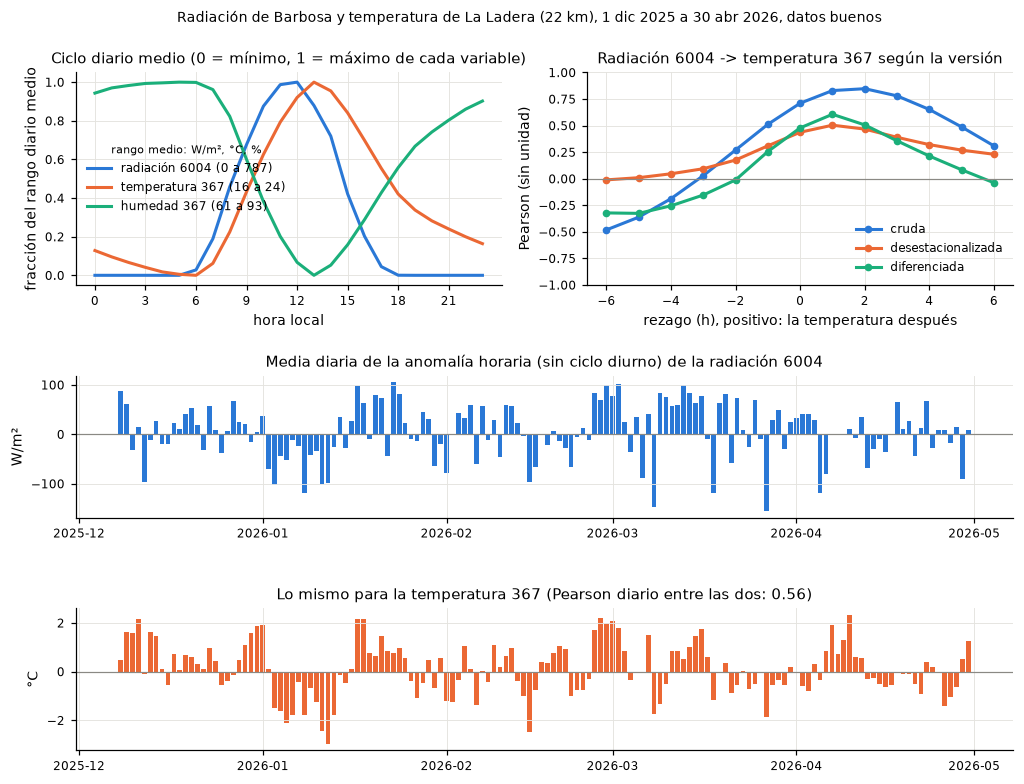

In [15]:
fig = plt.figure(figsize=(11, 8))
gs = fig.add_gridspec(3, 2, height_ratios=[1.2, 0.8, 0.8], hspace=0.55)
a0 = fig.add_subplot(gs[0, 0])
ciclo = H[["rad", "t", "h"]].groupby(H.index.hour).mean()
normal = (ciclo - ciclo.min()) / (ciclo.max() - ciclo.min())
for i, (col, nombre) in enumerate([("rad", "radiación 6004"), ("t", "temperatura 367"), ("h", "humedad 367")]):
    a0.plot(normal.index, normal[col], color=COLORES[i], label=f"{nombre} ({ciclo[col].min():.0f} a {ciclo[col].max():.0f})")
a0.set(title="Ciclo diario medio (0 = mínimo, 1 = máximo de cada variable)", xlabel="hora local",
       ylabel="fracción del rango diario medio", xticks=range(0, 24, 3))
a0.legend(loc="center left", title="rango medio: W/m², °C, %", title_fontsize=7)
a1 = fig.add_subplot(gs[0, 1])
for i, (version, g) in enumerate(cruz[cruz["par"] == "radiacion 6004 vs t 367 (1 h)"].groupby("version", sort=False)):
    a1.plot(g["rezago_min"] / 60, g["valor"], marker="o", markersize=4, color=COLORES[i], label=version)
a1.axhline(0, color=GRIS, linewidth=0.8)
a1.set(title="Radiación 6004 -> temperatura 367 según la versión", xlabel="rezago (h), positivo: la temperatura después",
       ylabel="Pearson (sin unidad)", ylim=(-1, 1))
a1.legend()
a2 = fig.add_subplot(gs[1, :])
a2.bar(anom_d.index, anom_d["rad"], color=COLORES[0], width=0.8)
a2.set(title="Media diaria de la anomalía horaria (sin ciclo diurno) de la radiación 6004", ylabel="W/m²")
a3 = fig.add_subplot(gs[2, :], sharex=a2)
a3.bar(anom_d.index, anom_d["t"], color=COLORES[1], width=0.8)
a3.set(title=f"Lo mismo para la temperatura 367 (Pearson diario entre las dos: {anom_d['rad'].corr(anom_d['t']):.2f})",
       ylabel="°C")
for a in (a2, a3):
    a.axhline(0, color=GRIS, linewidth=0.8)
fig.suptitle("Radiación de Barbosa y temperatura de La Ladera (22 km), 1 dic 2025 a 30 abr 2026, datos buenos", fontsize=9, y=0.95)
guardar(fig, "radiacion_temperatura")
plt.show()

## D4. Medidas distintas de Pearson y significancia con autocorrelación

- Pearson mide relación lineal y la dominan los valores extremos.
- Spearman (Pearson sobre rangos) sirve con relaciones monótonas no lineales y colas pesadas. Con lluvia hay muchos empates en cero, así que también se queda corto.
- La información mutua (estimador de k vecinos de scikit-learn) capta cualquier dependencia, también no monótona. Aquí se expresa como coeficiente informacional de Linfoot, r = raíz(1 - exp(-2 I)), que vale lo mismo que |Pearson| si los datos son normales bivariados; así se puede comparar en la misma escala de 0 a 1. No tiene signo.
- La correlación cruzada agrega el rezago: dice cuándo, además de cuánto.

In [16]:
tabla = corr[corr["version"] == "cruda"].pivot_table(index="par", columns="metodo", values="valor", sort=False)
print(tabla.round(3))

x, y = rad_v["desestacionalizada"], t_v["desestacionalizada"]
print(f"\nautocorrelación de rezago 1 h de las anomalías: radiación {x.autocorr(1):.2f}, temperatura {y.autocorr(1):.2f}")
for bloque in (1, 24, 72, 168):
    bajo, alto = R.ic_bootstrap_bloques(x, y, bloque, n=300)
    print(f"IC 95 % de Pearson rad-t desestacionalizada con bloque de {bloque:>3} h: [{bajo:.3f}, {alto:.3f}] ancho {alto - bajo:.3f}")
r_c, n_c = R.correlacion(x, y)
xy = pd.concat([x, y], axis=1).dropna()
print(f"valor p 'de libro' (supone {n_c} horas independientes): {stats.pearsonr(xy.iloc[:, 0], xy.iloc[:, 1]).pvalue:.1e}")

metodo                               pearson  spearman  info_mutua  circular
par                                                                         
t 367 vs h 367 (1 h)                  -0.952    -0.913       0.943       NaN
t 367 vs presion de vapor 367 (1 h)    0.101     0.244       0.586       NaN
t 367 vs pr 367 (1 h)                 -0.615    -0.522       0.692       NaN
vv 367 vs vv_max 367 (1 min)           0.874     0.862       0.903       NaN
dv 367 vs dv_max 367 (1 min)             NaN       NaN         NaN     0.809
p 367 vs h 367 (1 h)                   0.106     0.142       0.302       NaN
lluvia 35 vs h 367 (1 h)               0.094     0.219       0.284       NaN
p1 35 vs p2 35 (1 min)                 0.861     0.603       0.228       NaN
p1 35 vs p2 35 (10 min)                0.994     0.802       0.496       NaN
p1 35 vs p2 35 (1 h)                   0.999     0.886       0.722       NaN
p1 35 vs p2 35 (1 día)                 0.999     0.990       0.994       NaN

Cuándo conviene cada una, con lo que se vio aquí:

- Lluvia (muchos ceros y colas pesadas): Pearson la dominan unas pocas horas extremas. Con lluvia frente a humedad Pearson da 0,094 y Spearman 0,219. En D5, Pearson favorece la intensidad (0,62 frente a 0,54 del total) solo por los tres eventos más grandes; Spearman invierte el orden.
- Relaciones no lineales: t frente a presión de vapor da 0,10 con Pearson y 0,59 con información mutua; la dependencia existe pero no es una recta.
- Direcciones: ni Pearson ni Spearman; correlación circular y diferencia angular.
- Rezagos: la correlación cruzada da el cuándo (2 h de la radiación a la temperatura, 10 min de la lluvia al nivel, 0 min entre pluviómetros).

Sobre significancia: con 3401 horas el valor p de Pearson sale del orden de 1e-159, pero supone horas independientes y no lo son (autocorrelación de rezago 1 de 0,67 y 0,89 en las anomalías). El bootstrap clásico da un intervalo de ancho 0,064; con bloques de 72 h el ancho es 0,113, casi el doble. Cambiar el bloque entre 24 y 168 h mueve poco el ancho (0,101 a 0,113), así que el resultado no depende de esa elección. Por eso en la tabla se reportan intervalos por bloques y no valores p.

## D5. Hipótesis: la subida del nivel en la 803 depende más de la intensidad máxima en 10 o 30 minutos que del acumulado del evento

Método:

- Evento de lluvia en la 35: tramo con lluvia separado de otro por al menos 60 minutos secos, con 5 mm o más.
- Por evento: total (mm), duración, intensidad máxima como lluvia acumulada en 10, 30 y 60 minutos, y lluvia de las 24 h previas (humedad antecedente).
- Subida del nivel: máximo de la mediana móvil de 3 minutos entre el inicio y una hora después del fin, menos la mediana de la hora previa al inicio.
- Piso de ruido: la misma subida calculada en 500 ventanas sin lluvia de la misma duración. Lo que esté por debajo no se distingue del ruido del sensor.
- Contraste: Spearman de la subida con cada variable, intervalo por bootstrap de eventos (son casi independientes entre sí), diferencia entre la correlación con la intensidad y con el total (si su intervalo excluye 0 la hipótesis se sostiene) y Spearman parcial para separar dos variables que van juntas.

In [17]:
def contraste(lluvia, nombre):
    ev = R.eventos_lluvia(lluvia)
    ev = ev.join(R.respuesta_nivel(ev, nivel)).dropna(subset=["subida_cm"])
    piso = R.subida_en_seco(lluvia, nivel, int(ev["duracion_min"].median()), n=500)
    y = ev["subida_cm"].to_numpy()
    boot = lambda f, *cols: stats.bootstrap(tuple(ev[c].to_numpy() for c in cols) + (y,), f, paired=True,
                                            vectorized=False, n_resamples=2000, method="percentile",
                                            rng=np.random.default_rng(0)).confidence_interval
    res = []
    for c in ["total", "i10", "i30", "i60", "duracion_min", "previa_24h"]:
        ic = boot(lambda a, b: stats.spearmanr(a, b)[0], c)
        res.append({"variable": c, "spearman": stats.spearmanr(ev[c], y)[0], "ic95_inf": ic.low, "ic95_sup": ic.high,
                    "pearson": stats.pearsonr(ev[c], y)[0]})
    res = pd.DataFrame(res).set_index("variable")
    print(f"--- {nombre}: {len(ev)} eventos, mediana {ev['total'].median():.1f} mm, "
          f"minutos sin dato dentro de eventos {int(ev['sin_dato_min'].sum())}")
    print(f"piso de ruido (subida en ventanas secas): mediana {piso.median():.1f} cm, percentil 95 {piso.quantile(.95):.1f} cm "
          f"({piso.notna().sum()} ventanas); eventos por encima: {(ev['subida_cm'] > piso.quantile(.95)).sum()}")
    print(f"minutos del inicio al pico: mediana {ev['min_al_pico'].median():.0f}")
    print(res.round(3))
    for c in ("i10", "i30"):
        d = boot(lambda a, b, yy: stats.spearmanr(a, yy)[0] - stats.spearmanr(b, yy)[0], c, "total")
        print(f"Spearman({c}) - Spearman(total): {res.loc[c, 'spearman'] - res.loc['total', 'spearman']:.3f}, IC 95 % [{d.low:.3f}, {d.high:.3f}]; "
              f"parcial {c} | total {R.spearman_parcial(ev, c, 'subida_cm', 'total'):.3f}, "
              f"parcial total | {c} {R.spearman_parcial(ev, 'total', 'subida_cm', c):.3f}")
    print(f"Spearman entre i30 y total: {stats.spearmanr(ev['i30'], ev['total'])[0]:.3f}")
    return ev, piso


ev_buena, piso_buena = contraste(lluvia35, "lluvia con bandera buena")
ev_sens, piso_sens = contraste(lluvia35_sens, "lluvia con los minutos de p1_p2_difieren devueltos")

--- lluvia con bandera buena: 43 eventos, mediana 11.7 mm, minutos sin dato dentro de eventos 0
piso de ruido (subida en ventanas secas): mediana 2.1 cm, percentil 95 9.8 cm (478 ventanas); eventos por encima: 5
minutos del inicio al pico: mediana 23
              spearman  ic95_inf  ic95_sup  pearson
variable                                           
total            0.377     0.044     0.657    0.568
i10              0.263    -0.105     0.579    0.573
i30              0.294    -0.079     0.612    0.622
i60              0.333    -0.021     0.629    0.606
duracion_min     0.153    -0.143     0.465    0.091
previa_24h       0.296    -0.015     0.570    0.212


Spearman(i10) - Spearman(total): -0.114, IC 95 % [-0.297, 0.053]; parcial i10 | total -0.048, parcial total | i10 0.284


Spearman(i30) - Spearman(total): -0.084, IC 95 % [-0.248, 0.064]; parcial i30 | total -0.055, parcial total | i30 0.253
Spearman entre i30 y total: 0.850


--- lluvia con los minutos de p1_p2_difieren devueltos: 46 eventos, mediana 9.9 mm, minutos sin dato dentro de eventos 0
piso de ruido (subida en ventanas secas): mediana 2.2 cm, percentil 95 9.8 cm (478 ventanas); eventos por encima: 5
minutos del inicio al pico: mediana 22
              spearman  ic95_inf  ic95_sup  pearson
variable                                           
total            0.351     0.012     0.617    0.539
i10              0.221    -0.139     0.521    0.567
i30              0.263    -0.099     0.567    0.620
i60              0.304    -0.049     0.598    0.601
duracion_min     0.225    -0.066     0.481    0.087
previa_24h       0.311     0.044     0.557    0.200


Spearman(i10) - Spearman(total): -0.129, IC 95 % [-0.293, 0.047]; parcial i10 | total -0.046, parcial total | i10 0.282


Spearman(i30) - Spearman(total): -0.088, IC 95 % [-0.249, 0.063]; parcial i30 | total -0.038, parcial total | i30 0.244
Spearman entre i30 y total: 0.809


             inicio  total  i10  i30  previa_24h  subida_cm  min_al_pico
2026-03-27 09:53:00   27.6 16.8 26.8         0.8       31.6         23.0
2026-01-12 15:48:00   20.2  7.0 14.1        36.8       25.6         27.0
2026-04-03 16:02:00   43.6 16.1 35.4         1.0       25.2         28.0
forma del pico del 27 de marzo, minuto a minuto (nivel crudo, bandera propia y lluvia p1):
fecha_hora  2026-03-27 10:10:00  2026-03-27 10:11:00  2026-03-27 10:12:00  2026-03-27 10:13:00  2026-03-27 10:14:00  2026-03-27 10:15:00  2026-03-27 10:16:00  2026-03-27 10:17:00  2026-03-27 10:18:00  2026-03-27 10:19:00  2026-03-27 10:20:00  2026-03-27 10:21:00  2026-03-27 10:22:00
nivel_cm                 10.500                5.400                 0.30                1.700                0.700               32.200               32.000               36.200               28.700                  7.4                6.400                  5.0                4.700
bandera                   1.000                1.

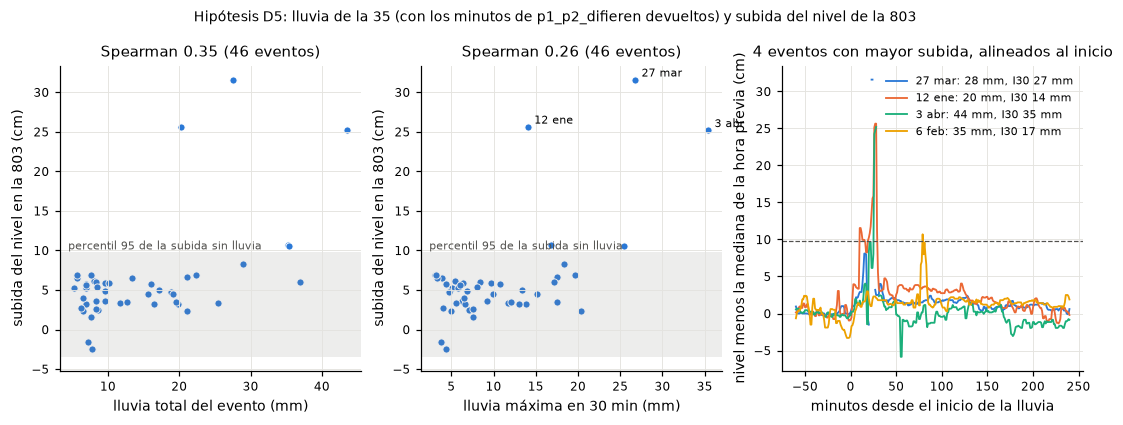

In [18]:
mayores = ev_sens.nlargest(3, "subida_cm")
print(mayores[["inicio", "total", "i10", "i30", "previa_24h", "subida_cm", "min_al_pico"]].to_string(index=False, float_format="%.1f"))
m803 = pd.read_parquet(DIR_SALIDAS / "minutal_803.parquet")
print("forma del pico del 27 de marzo, minuto a minuto (nivel crudo, bandera propia y lluvia p1):")
print(pd.DataFrame({"nivel_cm": m803["nivel"].round(1), "bandera": m803["b_nivel"], "p1_mm": r35["p1"]})
      .loc["2026-03-27 10:10":"2026-03-27 10:22"].T.to_string())
# minutos del nivel que el control propio no dejó como buenos dentro de las ventanas de los eventos
f803 = fallas.query("codigo == '803'")
for _, e in mayores.iterrows():
    w = f803[(f803["fecha_hora"] >= e["inicio"]) & (f803["fecha_hora"] <= e["fin"] + pd.Timedelta("60min"))]
    print(fecha(e["inicio"]), "minutos marcados en el nivel:", w.groupby("prueba").size().to_dict())

fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
umbral = piso_sens.quantile(0.95)
for a, (col, nombre) in zip(ax[:2], [("total", "lluvia total del evento (mm)"), ("i30", "lluvia máxima en 30 min (mm)")]):
    a.scatter(ev_sens[col], ev_sens["subida_cm"], s=22, color=COLORES[0], edgecolors="white", linewidths=0.6)
    a.axhspan(ev_sens["subida_cm"].min() - 1, umbral, color=GRIS, alpha=0.15, linewidth=0)
    a.text(a.get_xlim()[0], umbral, "  percentil 95 de la subida sin lluvia", ha="left", va="bottom", fontsize=7, color="#52514e")
    rho = stats.spearmanr(ev_sens[col], ev_sens["subida_cm"])[0]
    a.set(xlabel=nombre, ylabel="subida del nivel en la 803 (cm)", title=f"Spearman {rho:.2f} ({len(ev_sens)} eventos)")
for _, e in mayores.iterrows():
    ax[1].annotate(fecha(e["inicio"]), (e["i30"], e["subida_cm"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
for i, (_, e) in enumerate(ev_sens.nlargest(4, "subida_cm").iterrows()):
    tramo = nivel.loc[e["inicio"] - pd.Timedelta("60min"):e["inicio"] + pd.Timedelta("240min")]
    base = nivel.loc[e["inicio"] - pd.Timedelta("60min"):e["inicio"] - pd.Timedelta("1min")].median()
    minutos = (tramo.index - e["inicio"]) / pd.Timedelta("1min")
    ax[2].plot(minutos, tramo.rolling(3, center=True, min_periods=2).median() - base, linewidth=1.2,
               color=COLORES[i], label=f"{fecha(e['inicio'])}: {e['total']:.0f} mm, I30 {e['i30']:.0f} mm")
ax[2].axhline(umbral, color="#52514e", linewidth=0.8, linestyle="--")
ax[2].set(title="4 eventos con mayor subida, alineados al inicio", xlabel="minutos desde el inicio de la lluvia",
          ylabel="nivel menos la mediana de la hora previa (cm)")
ax[2].legend(fontsize=7, loc="upper right")
fig.suptitle("Hipótesis D5: lluvia de la 35 (con los minutos de p1_p2_difieren devueltos) y subida del nivel de la 803",
             fontsize=9, y=1.02)
guardar(fig, "hipotesis_nivel")
plt.show()

Resultado: la hipótesis no se confirma. Con los 46 eventos de la serie con los minutos de `p1_p2_difieren` devueltos, el Spearman de la subida es 0,35 con el total (IC 95 % de 0,01 a 0,62), 0,22 con la intensidad en 10 minutos y 0,26 en 30 minutos. La diferencia entre intensidad en 30 minutos y total es -0,09 con intervalo de -0,25 a 0,06: incluye el cero, así que no se puede decir que la intensidad explique más que el acumulado, y si algo apunta al revés. La parcial de la intensidad quitando el total es casi cero (-0,04) y la del total quitando la intensidad es 0,24. Con la serie de solo bandera buena (43 eventos) el resultado es parecido: Spearman de 0,38 con el total (IC 95 % de 0,04 a 0,66) y la diferencia entre intensidad y total incluye el cero.

Por qué el contraste es pobre, y qué haría:

- Intensidad y total van juntos (Spearman 0,81 entre la intensidad en 30 minutos y el total): con 46 eventos cuesta separarlos.
- El piso de ruido del nivel es alto: en ventanas secas la misma medida sube 2,2 cm en mediana y 9,8 cm en el percentil 95. Solo 5 de los 46 eventos lo superan.
- La humedad antecedente aparece (Spearman 0,31 con la lluvia de las 24 h previas, IC de 0,04 a 0,56). Por ejemplo, el 12 de enero en la tarde cayeron 20,2 mm y el nivel subió 25,6 cm porque en las 24 h previas ya habían caído 36,8 mm; el 3 de abril cayeron 43,6 mm, con más del doble de intensidad, y subió 25,2 cm con solo 1,0 mm previo.
- Los picos grandes duran pocos minutos: en el 27 de marzo el nivel salta de 0,7 a 32,2 cm en un minuto, se queda unos cuatro minutos cerca de 30 cm y baja a 7,4 cm en otro minuto. El control propio marca como salto los 4 minutos de los bordes de ese pico y 2 del 3 de abril, porque el umbral de 20 cm por minuto es del tamaño de estas subidas. Con los datos no puedo decir si es una quebrada muy rápida o un efecto del sensor bajo aguacero; hay que preguntarlo al equipo de hidrología. Propuesta para `calidad.py`: que el salto en el nivel, igual que `pico_sin_lluvia`, mire la lluvia de la 35 antes de marcar.
- Con más eventos (un año completo), separando por humedad antecedente y con caudal en vez de nivel (curva de calibración), el contraste sería mucho más firme.

El tiempo mediano del inicio de la lluvia al pico es de 22 minutos, del mismo orden que el rezago de 10 minutos del máximo de la correlación cruzada.

## Salidas para el dashboard

In [19]:
corr = pd.DataFrame(filas)
corr.to_csv(DIR_RESULTADOS / "correlaciones.csv", index=False, float_format="%.4f")
cruz.to_csv(DIR_RESULTADOS / "correlacion_cruzada.csv", index=False, float_format="%.4f")
print(corr.shape, cruz.shape, corr["par"].nunique(), "pares;", cruz["par"].nunique(), "pares con rezagos")
print(f"tiempo de ejecución: {time.time() - reloj:.0f} s")

(106, 8) (183, 4) 17 pares; 6 pares con rezagos
tiempo de ejecución: 48 s
